In [ ]:
import numpy as np
import pandas as pd

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving MobileSales.csv to MobileSales.csv


In [ ]:
df = pd.read_csv("MobileSales.csv")
print("Dataset Preview:\n", df.head())

Dataset Preview:
     Brands        Models         Colors                Mobile Memory  Storage  \
0  SAMSUNG  GALAXY M31S    Mirage Black  SAMSUNG GALAXY M31S       8      128   
1    Nokia           3.2          Steel             Nokia 3.2      2       16   
2   realme           C2   Diamond Black            realme C2       2       89   
3  Infinix        Note 5       Ice Blue        Infinix Note 5      4       64   
4    Apple    iPhone 11           Black      Apple iPhone 11       4       64   

   Selling Price  Original Price  Discount  Rating  
0          19330           20999      1669     4.3  
1          10199           10199         0     3.8  
2           6999            7999      1000     4.4  
3          12999           12999         0     4.2  
4          49900           49900         0     4.6  


### 1. Data Inspection and Cleaning
First, let's look at the data types and check for missing values to see what needs fixing.

In [ ]:
# Check data types and null counts
print(df.info())
print("\nMissing values per column:\n", df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3114 entries, 0 to 3113
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Brands          3114 non-null   object 
 1   Models          3114 non-null   object 
 2   Colors          3114 non-null   object 
 3   Mobile          3114 non-null   object 
 4   Memory          3114 non-null   object 
 5   Storage         3114 non-null   int64  
 6   Selling Price   3114 non-null   int64  
 7   Original Price  3114 non-null   int64  
 8   Discount        3114 non-null   int64  
 9   Rating          3114 non-null   float64
dtypes: float64(1), int64(4), object(5)
memory usage: 243.4+ KB
None

Missing values per column:
 Brands            0
Models            0
Colors            0
Mobile            0
Memory            0
Storage           0
Selling Price     0
Original Price    0
Discount          0
Rating            0
dtype: int64


### 2. Type Casting and Cleaning
We will ensure numeric columns are correctly typed and clean any string inconsistencies.

In [ ]:
# Convert memory and storage to numeric, handling errors just in case there are non-numeric strings
df['Memory'] = pd.to_numeric(df['Memory'], errors='coerce')
df['Storage'] = pd.to_numeric(df['Storage'], errors='coerce')

# Ensure price and discount are floats/ints
df['Selling Price'] = pd.to_numeric(df['Selling Price'], errors='coerce')
df['Original Price'] = pd.to_numeric(df['Original Price'], errors='coerce')

# Trim whitespace from string columns
str_cols = ['Brands', 'Models', 'Colors', 'Mobile']
for col in str_cols:
    df[col] = df[col].str.strip()

print("Cleaning complete. Updated Data Types:")
display(df.dtypes)
display(df.head())

Cleaning complete. Updated Data Types:


,0
Brands,object
Models,object
Colors,object
Mobile,object
Memory,float64
Storage,int64
Selling Price,int64
Original Price,int64
Discount,int64
Rating,float64


,Brands,Models,Colors,Mobile,Memory,Storage,Selling Price,Original Price,Discount,Rating
0,SAMSUNG,GALAXY M31S,Mirage Black,SAMSUNG GALAXY M31S,8.0,128,19330,20999,1669,4.3
1,Nokia,3.2,Steel,Nokia 3.2,2.0,16,10199,10199,0,3.8
2,realme,C2,Diamond Black,realme C2,2.0,89,6999,7999,1000,4.4
3,Infinix,Note 5,Ice Blue,Infinix Note 5,4.0,64,12999,12999,0,4.2
4,Apple,iPhone 11,Black,Apple iPhone 11,4.0,64,49900,49900,0,4.6


### 3. Exploratory Data Analysis (EDA)
We will now group the data by brand to analyze average pricing and consumer ratings.

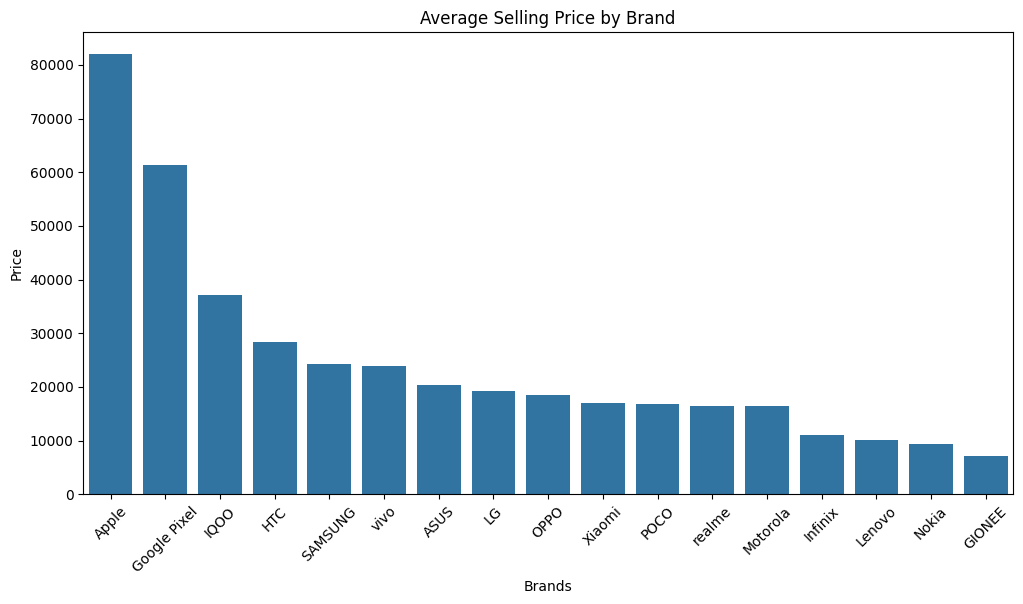

Brand-wise Averages:
              Selling Price    Rating
Brands                               
Apple          81985.560724  4.519380
Google Pixel   61391.862069  4.506897
IQOO           37190.000000  4.400000
HTC            28314.381818  3.969091
SAMSUNG        24296.248957  4.208067
vivo           23866.241935  4.370968
ASUS           20326.915254  4.089831
LG             19323.181818  3.983838
OPPO           18560.488462  4.295000
Xiaomi         16941.909091  4.301515
POCO           16870.621622  4.385135
realme         16396.535168  4.381040
Motorola       16357.466667  4.143810
Infinix        11092.178808  4.276821
Lenovo         10083.842975  3.976860
Nokia           9428.657277  4.023944
GIONEE          7135.093023  3.856589


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average price and rating per brand
brand_analysis = df.groupby('Brands').agg({
    'Selling Price': 'mean',
    'Rating': 'mean'
}).sort_values(by='Selling Price', ascending=False)

# Plotting
plt.figure(figsize=(12, 6))
sns.barplot(x=brand_analysis.index, y=brand_analysis['Selling Price'])
plt.xticks(rotation=45)
plt.title('Average Selling Price by Brand')
plt.ylabel('Price')
plt.show()

print("Brand-wise Averages:")
print(brand_analysis)

### 4. Correlation Analysis
We will calculate the numerical correlation between `Selling Price` and `Rating` and visualize it using a scatter plot.

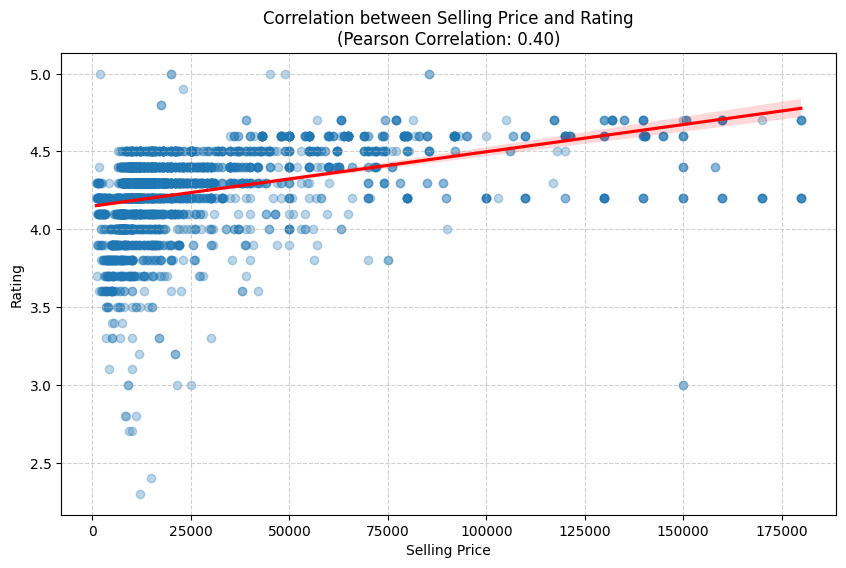

The Pearson correlation coefficient is: 0.3955


In [ ]:
# Calculate Pearson correlation
correlation = df['Selling Price'].corr(df['Rating'])

# Visualize the relationship
plt.figure(figsize=(10, 6))
sns.regplot(x='Selling Price', y='Rating', data=df, scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title(f'Correlation between Selling Price and Rating\n(Pearson Correlation: {correlation:.2f})')
plt.xlabel('Selling Price')
plt.ylabel('Rating')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print(f"The Pearson correlation coefficient is: {correlation:.4f}")

### 5. Discount vs. Rating Analysis
We will now check if there is a relationship between the discount offered and the customer rating.

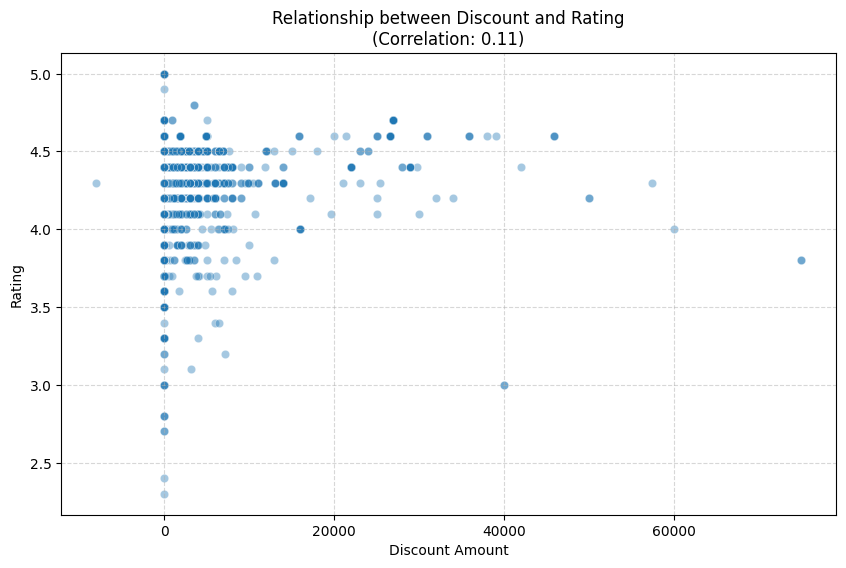

The correlation between Discount and Rating is: 0.1119


In [ ]:
# Calculate correlation between Discount and Rating
discount_corr = df['Discount'].corr(df['Rating'])

# Visualize the relationship
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Discount', y='Rating', data=df, alpha=0.4)
plt.title(f'Relationship between Discount and Rating\n(Correlation: {discount_corr:.2f})')
plt.xlabel('Discount Amount')
plt.ylabel('Rating')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"The correlation between Discount and Rating is: {discount_corr:.4f}")

### 6. Identifying 'Best Value' Models
We define 'Best Value' as models with a high rating (>= 4.5) and a price lower than the overall median price.

In [ ]:
median_price = df['Selling Price'].median()
best_value = df[(df['Rating'] >= 4.5) & (df['Selling Price'] <= median_price)]

print(f"Overall Median Price: {median_price}")
print(f"Found {len(best_value)} Best Value models.")
print("\nTop 10 Best Value Models (High Rating, Lower Price):")
display(best_value[['Brands', 'Models', 'Selling Price', 'Rating']].sort_values(by='Rating', ascending=False).head(10))

Overall Median Price: 15000.0
Found 79 Best Value models.

Top 10 Best Value Models (High Rating, Lower Price):


,Brands,Models,Selling Price,Rating
2242,SAMSUNG,SM-B310EZDDINS,1949,5.0
40,realme,Narzo 10,11999,4.5
30,SAMSUNG,Galaxy J6,14990,4.5
77,Infinix,Note 11,14999,4.5
113,realme,C35,12999,4.5
162,OPPO,A53,11990,4.5
50,realme,9i,13999,4.5
244,OPPO,A53,13499,4.5
268,realme,5i,10999,4.5
271,realme,2,9990,4.5


In [ ]:
import pandas as pd

# Identify top 10 best phones based on Rating (secondary sort by Selling Price for value)
top_10_best = df.sort_values(by=['Rating', 'Selling Price'], ascending=[False, True]).head(10)

# Identify top 10 worst phones based on Rating
top_10_worst = df.sort_values(by='Rating', ascending=True).head(10)

print("--- Top 10 Best Rated Phones ---")
display(top_10_best[['Brands', 'Models', 'Selling Price', 'Rating']])

print("\n--- Top 10 Worst Rated Phones ---")
display(top_10_worst[['Brands', 'Models', 'Selling Price', 'Rating']])

--- Top 10 Best Rated Phones ---


,Brands,Models,Selling Price,Rating
2242,SAMSUNG,SM-B310EZDDINS,1949,5.0
1446,vivo,Z1x,19990,5.0
2879,vivo,S2,19990,5.0
247,vivo,X50,44990,5.0
1655,vivo,X60 Pro,48780,5.0
2483,Apple,iPhone 7 Plus,85400,5.0
2634,Apple,iPhone 7 Plus,85400,5.0
675,vivo,Y33T,22990,4.9
1847,realme,9 5G,17499,4.8
2179,realme,9 5G,17499,4.8



--- Top 10 Worst Rated Phones ---


,Brands,Models,Selling Price,Rating
1781,Xiaomi,Redmi Note 8,11999,2.3
1638,Motorola,Quench X T3,14939,2.4
1488,GIONEE,M7,9964,2.7
1263,GIONEE,M7,9290,2.7
1240,GIONEE,G3,10990,2.8
1322,GIONEE,S11,8389,2.8
2583,GIONEE,S11,8539,2.8
3034,OPPO,R1 R829,24990,3.0
1975,SAMSUNG,Sm-G361Hhadins,8999,3.0
1595,SAMSUNG,Galaxy Fold 2,149999,3.0


### 8. Discount Strategy Analysis
We will calculate the discount percentage and analyze it by Brand and Storage to find the 'sweet spot' and identify stock clearance patterns.

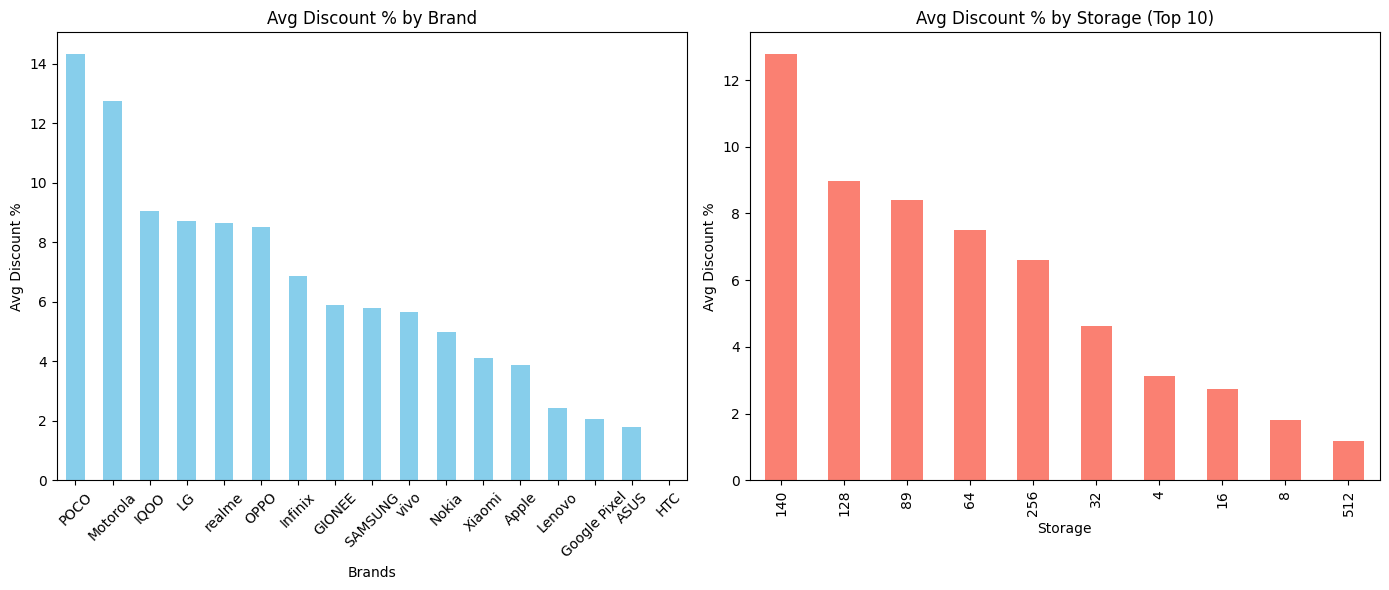

Top 5 Heavily Discounted Brands:
Brands
POCO        14.346840
Motorola    12.750690
IQOO         9.065627
LG           8.718038
realme       8.662233
Name: Discount_Percentage, dtype: float64

Correlation between Original Price and Discount Percentage:
0.04920905054438184


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate Discount Percentage
df['Discount_Percentage'] = (df['Discount'] / df['Original Price']) * 100

# 1. Brands with the highest average discount percentage
brand_discount = df.groupby('Brands')['Discount_Percentage'].mean().sort_values(ascending=False)

# 2. Storage configurations with highest average discount percentage
storage_discount = df.groupby('Storage')['Discount_Percentage'].mean().sort_values(ascending=False)

plt.figure(figsize=(14, 6))

# Plot Brand Discount Patterns
plt.subplot(1, 2, 1)
brand_discount.plot(kind='bar', color='skyblue')
plt.title('Avg Discount % by Brand')
plt.ylabel('Avg Discount %')
plt.xticks(rotation=45)

# Plot Storage Discount Patterns
plt.subplot(1, 2, 2)
storage_discount.head(10).plot(kind='bar', color='salmon')
plt.title('Avg Discount % by Storage (Top 10)')
plt.ylabel('Avg Discount %')

plt.tight_layout()
plt.show()

print("Top 5 Heavily Discounted Brands:")
print(brand_discount.head(5))

print("\nCorrelation between Original Price and Discount Percentage:")
print(df['Original Price'].corr(df['Discount_Percentage']))

### 9. Identifying Value Drivers for Customer Satisfaction
We will analyze how Memory and Storage impact user ratings to understand what technical specs consumers value most.

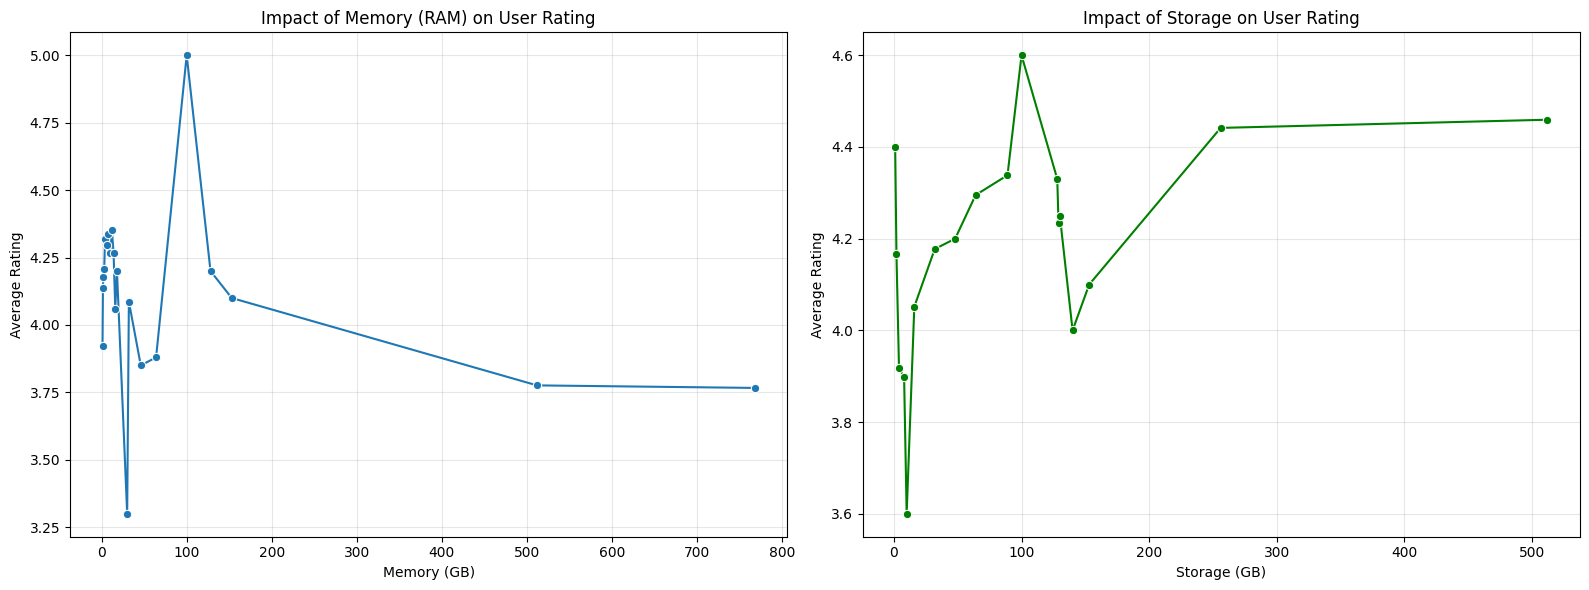

Correlation Matrix (Specs vs Rating):


,Rating
Memory,-0.224330
Storage,0.384377
Rating,1.000000


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by Memory to see average rating trends
mem_rating = df.groupby('Memory')['Rating'].mean().reset_index()
# Group by Storage to see average rating trends
storage_rating = df.groupby('Storage')['Rating'].mean().reset_index()

plt.figure(figsize=(16, 6))

# Plot Rating vs Memory
plt.subplot(1, 2, 1)
sns.lineplot(data=mem_rating, x='Memory', y='Rating', marker='o')
plt.title('Impact of Memory (RAM) on User Rating')
plt.xlabel('Memory (GB)')
plt.ylabel('Average Rating')
plt.grid(True, alpha=0.3)

# Plot Rating vs Storage
plt.subplot(1, 2, 2)
sns.lineplot(data=storage_rating, x='Storage', y='Rating', marker='o', color='green')
plt.title('Impact of Storage on User Rating')
plt.xlabel('Storage (GB)')
plt.ylabel('Average Rating')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Statistical correlation
print("Correlation Matrix (Specs vs Rating):")
display(df[['Memory', 'Storage', 'Rating']].corr()[['Rating']])

### 10. Smart Inventory Segmentation
We will segment the phones based on price quartiles:
*   **Budget**: Bottom 25% of prices.
*   **Mid-Tier**: 25th to 75th percentile.
*   **Premium**: 75th to 90th percentile.
*   **Luxury**: Top 10% of prices.

In [ ]:
import pandas as pd
import numpy as np

# Define price tiers based on quantiles
price_bins = [0, df['Selling Price'].quantile(0.25), df['Selling Price'].quantile(0.75), df['Selling Price'].quantile(0.90), np.inf]
labels = ['Budget', 'Mid-Tier', 'Premium', 'Luxury']

df['Market_Segment'] = pd.cut(df['Selling Price'], bins=price_bins, labels=labels)

# Calculate segment statistics with observed=True to fix the FutureWarning
segment_analysis = df.groupby('Market_Segment', observed=True).agg({
    'Models': 'count',
    'Selling Price': 'mean',
    'Discount_Percentage': 'mean',
    'Rating': 'mean'
}).rename(columns={'Models': 'Unit_Count'})

print("Inventory Segment Summary:")
display(segment_analysis)

Inventory Segment Summary:


,Unit_Count,Selling Price,Discount_Percentage,Rating
Market_Segment,,,,
Budget,792,6580.248737,5.504473,4.051010
Mid-Tier,1557,16483.402055,6.902132,4.250803
Premium,457,43523.763676,5.281076,4.377681
Luxury,308,102458.045455,4.657933,4.478247


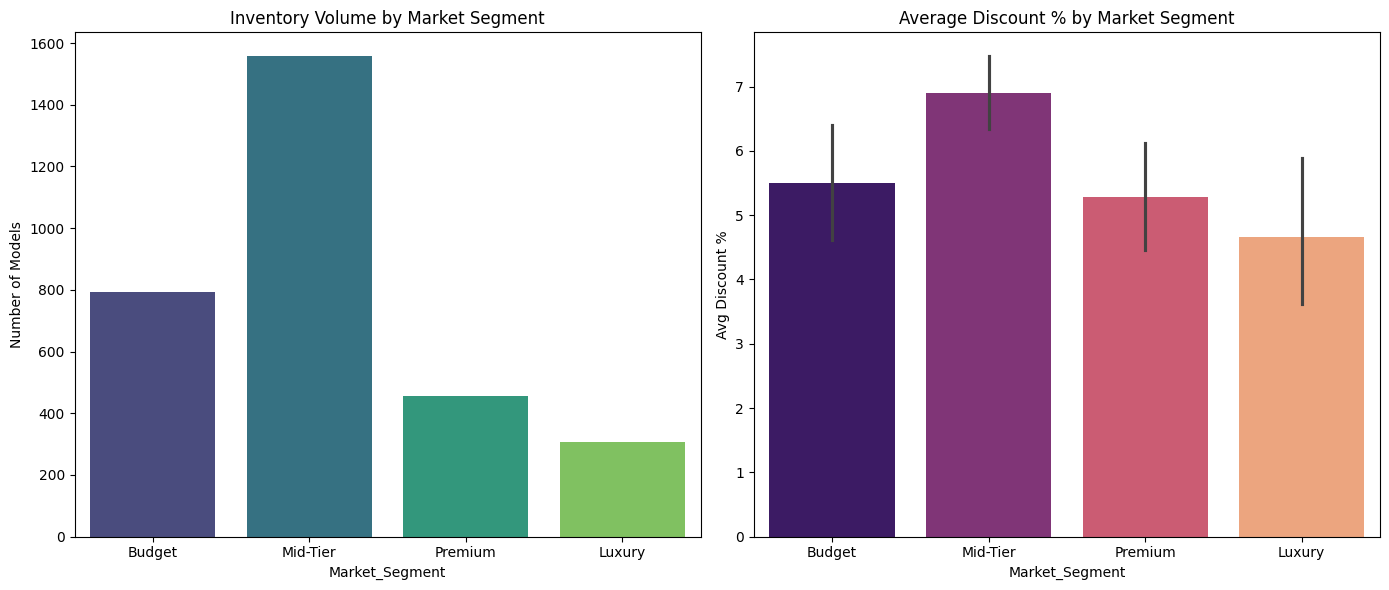

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

# Plot 1: Volume Distribution - Fixed palette/hue warning
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Market_Segment', hue='Market_Segment', palette='viridis', legend=False)
plt.title('Inventory Volume by Market Segment')
plt.ylabel('Number of Models')

# Plot 2: Discount Strategy by Segment - Fixed palette/hue warning
plt.subplot(1, 2, 2)
sns.barplot(data=df, x='Market_Segment', y='Discount_Percentage', hue='Market_Segment', palette='magma', legend=False)
plt.title('Average Discount % by Market Segment')
plt.ylabel('Avg Discount %')

plt.tight_layout()
plt.show()

In [ ]:
model_counts = df.groupby('Brands')['Models'].nunique().sort_values(ascending=False)
print("Number of unique models per brand:")
print(model_counts.head())

highest_models_brand = model_counts.index[0]
highest_models_count = model_counts.iloc[0]

print(f"\n{highest_models_brand} has the highest number of mobile models with {highest_models_count} unique models.")

Number of unique models per brand:
Brands
SAMSUNG    210
Nokia       83
OPPO        77
LG          64
realme      62
Name: Models, dtype: int64

SAMSUNG has the highest number of mobile models with 210 unique models.


1. Which mobile brand has the highest number of mobile models in the dataset?


In [ ]:
model_counts = df.groupby('Brands')['Models'].nunique().sort_values(ascending=False)
print("Number of unique models per brand:")
print(model_counts.head())

highest_models_brand = model_counts.index[0]
highest_models_count = model_counts.iloc[0]

print(f"\n{highest_models_brand} has the highest number of mobile models with {highest_models_count} unique models.")

Number of unique models per brand:
Brands
SAMSUNG    210
Nokia       83
OPPO        77
LG          64
realme      62
Name: Models, dtype: int64

SAMSUNG has the highest number of mobile models with 210 unique models.


2. Which are the top 10 mobile models based on their selling price?


In [ ]:
top_10_selling_price = df.sort_values(by='Selling Price', ascending=False).head(10)
print("\nTop 10 Mobile Models by Selling Price:")
display(top_10_selling_price[['Brands', 'Models', 'Selling Price', 'Rating']])


Top 10 Mobile Models by Selling Price:


,Brands,Models,Selling Price,Rating
1285,Apple,iPhone 13 Pro Max,179900,4.2
813,Apple,iPhone 13 Pro Max,179900,4.7
1185,Apple,iPhone 13 Pro Max,179900,4.2
831,Apple,iPhone 13 Pro Max,179900,4.7
323,Apple,iPhone 13 Pro Max,179900,4.2
903,Apple,iPhone 13 Pro Max,179900,4.7
1079,Apple,iPhone 13 Pro Max,179900,4.2
799,Apple,iPhone 13 Pro Max,179900,4.7
2032,Apple,iPhone 13 Pro Max,179900,4.2
923,SAMSUNG,Fold 2 5G,169999,4.2


3. What is the average selling price of mobiles for each brand?


In [ ]:
avg_selling_price_by_brand = df.groupby('Brands')['Selling Price'].mean().sort_values(ascending=False)
print("\nAverage Selling Price by Brand:")
display(avg_selling_price_by_brand)


Average Selling Price by Brand:


,Selling Price
Brands,
Apple,81985.560724
Google Pixel,61391.862069
IQOO,37190.000000
HTC,28314.381818
SAMSUNG,24296.248957
vivo,23866.241935
ASUS,20326.915254
LG,19323.181818
OPPO,18560.488462


4. Which mobile brand offers the highest average discount?


In [ ]:
highest_discount_brand = brand_discount.index[0]
highest_discount_percentage = brand_discount.iloc[0]

print(f"\n{highest_discount_brand} offers the highest average discount with an average of {highest_discount_percentage:.2f}%.")


POCO offers the highest average discount with an average of 14.35%.


5. Which mobile brands have the highest average customer rating, and how does their average selling
price compare?

In [ ]:
highest_rated_brands = df.groupby('Brands').agg({
    'Rating': 'mean',
    'Selling Price': 'mean'
}).sort_values(by='Rating', ascending=False)

print("\nMobile Brands by Average Customer Rating (Highest First) and Average Selling Price:")
display(highest_rated_brands)


Mobile Brands by Average Customer Rating (Highest First) and Average Selling Price:


,Rating,Selling Price
Brands,,
Apple,4.519380,81985.560724
Google Pixel,4.506897,61391.862069
IQOO,4.400000,37190.000000
POCO,4.385135,16870.621622
realme,4.381040,16396.535168
vivo,4.370968,23866.241935
Xiaomi,4.301515,16941.909091
OPPO,4.295000,18560.488462
Infinix,4.276821,11092.178808


6. How does mobile storage capacity affect the average selling price? Can you compare mobiles with
different storage options?

In [ ]:
storage_price_comparison = df.groupby('Storage')['Selling Price'].mean().sort_values(ascending=False)

print("\nAverage Selling Price by Storage Capacity:")
display(storage_price_comparison)


Average Selling Price by Storage Capacity:


,Selling Price
Storage,
1,171906.428571
512,121470.840580
256,66900.205761
128,30404.039948
89,26331.076923
130,22549.500000
129,22427.000000
64,21187.953668
32,14398.626102


/tmp/ipykernel_3728/222370451.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=storage_price_comparison.index, y=storage_price_comparison.values, palette='viridis')


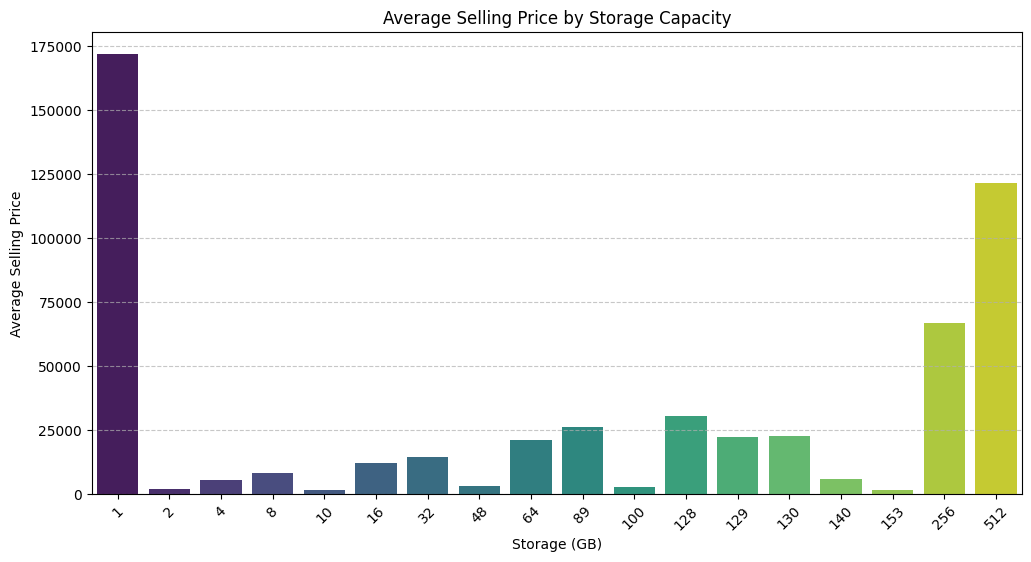

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(x=storage_price_comparison.index, y=storage_price_comparison.values, palette='viridis')
plt.title('Average Selling Price by Storage Capacity')
plt.xlabel('Storage (GB)')
plt.ylabel('Average Selling Price')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

7. Which mobile models provide the highest discount amount, and what percentage of their original
price is discounted?

In [ ]:
# Calculate Discount Percentage for each model
df['Discount_Percentage'] = (df['Discount'] / df['Original Price']) * 100

# Sort by 'Discount' in descending order to find models with highest discount amount
highest_discount_models = df.sort_values(by='Discount', ascending=False)

print("\nMobile Models with Highest Discount Amount and Percentage:")
display(highest_discount_models[['Brands', 'Models', 'Original Price', 'Discount', 'Discount_Percentage']].head(10))


Mobile Models with Highest Discount Amount and Percentage:


,Brands,Models,Original Price,Discount,Discount_Percentage
589,Motorola,Razr,149999,75000,50.000333
711,Motorola,Razr,149999,75000,50.000333
848,Motorola,Razr 5G,149999,60000,40.000267
306,ASUS,ROG,83999,57500,68.453196
2632,LG,Wing,80000,50001,62.501250
507,LG,Wing,80000,50001,62.501250
1428,Apple,iPhone XS Max,124900,45901,36.750200
911,Apple,iPhone XS Max,124900,45901,36.750200
410,Apple,iPhone XS Max,124900,45901,36.750200
1482,LG,G8X,70000,42010,60.014286


8. Which combination of memory and storage offers the best balance between selling price and
customer rating?

In [ ]:
# Group by Memory and Storage to calculate average selling price and rating
balance_analysis = df.groupby(['Memory', 'Storage']).agg({
    'Selling Price': 'mean',
    'Rating': 'mean'
}).reset_index()

# Calculate overall average rating and selling price for comparison
overall_avg_rating = df['Rating'].mean()
overall_avg_selling_price = df['Selling Price'].mean()

# Filter for combinations that have above-average rating and below-average selling price
best_balance = balance_analysis[
    (balance_analysis['Rating'] >= overall_avg_rating) &
    (balance_analysis['Selling Price'] <= overall_avg_selling_price)
]

# Sort by Rating (descending) and then by Selling Price (ascending) to find the 'best' balance
best_balance = best_balance.sort_values(by=['Rating', 'Selling Price'], ascending=[False, True])

print(f"\nOverall Average Rating: {overall_avg_rating:.2f}")
print(f"Overall Average Selling Price: {overall_avg_selling_price:.2f}")
print("\nCombinations of Memory and Storage offering the best balance (High Rating / Lower Price):")
display(best_balance)


Overall Average Rating: 4.24
Overall Average Selling Price: 26436.63

Combinations of Memory and Storage offering the best balance (High Rating / Lower Price):


,Memory,Storage,Selling Price,Rating
81,100.0,100,1949.000000,5.000000
44,8.0,89,22999.000000,4.425000
29,4.0,89,12998.100000,4.400000
19,3.0,89,10036.400000,4.310000
47,8.0,130,25999.000000,4.300000
34,6.0,64,20087.156250,4.293750
28,4.0,64,19497.406360,4.287809
50,10.0,2,2062.666667,4.266667
7,1.5,16,13097.555556,4.266667
46,8.0,129,24081.000000,4.250000


9. Can you identify the top 10 mobile models that provide the best value for money by considering
selling price, discount, storage, memory, and customer rating? Explain how you calculated the
value score.


In [ ]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Ensure Discount_Percentage is calculated, if not already
# This handles cases where 'Original Price' might be 0, leading to division by zero or NaN
if 'Discount_Percentage' not in df.columns:
    df['Discount_Percentage'] = (df['Discount'] / df['Original Price']) * 100
    df['Discount_Percentage'].replace([np.inf, -np.inf], np.nan, inplace=True)
    df['Discount_Percentage'].fillna(0, inplace=True) # Fill NaNs (e.g., from 0 original price) with 0 discount

# Handle potential NaN values in 'Memory' and 'Storage' introduced by previous type conversions
# Fill with the median of the respective column to avoid dropping valuable data
if df['Memory'].isnull().any():
    df['Memory'].fillna(df['Memory'].median(), inplace=True)
if df['Storage'].isnull().any():
    df['Storage'].fillna(df['Storage'].median(), inplace=True)

# Features to consider for the value score
features_for_value_score = ['Selling Price', 'Discount_Percentage', 'Storage', 'Memory', 'Rating']

# Initialize MinMaxScaler
scaler = MinMaxScaler()

# Create a temporary DataFrame for scaled values to avoid modifying original df columns directly
df_scaled_features = df[features_for_value_score].copy()
df_scaled_features[features_for_value_score] = scaler.fit_transform(df_scaled_features[features_for_value_score])

# Calculate the Value Score
# Lower Selling Price is better, so we inverse its scaled value (1 - scaled_price)
# Higher Discount_Percentage, Storage, Memory, and Rating are better.
df['Value_Score'] = (1 - df_scaled_features['Selling Price']) + \
                    df_scaled_features['Discount_Percentage'] + \
                    df_scaled_features['Storage'] + \
                    df_scaled_features['Memory'] + \
                    df_scaled_features['Rating']

# Display the top 10 models by Value Score
top_10_value_models = df.sort_values(by='Value_Score', ascending=False).head(10)

print("\nTop 10 Mobile Models by Value Score:")
display(top_10_value_models[['Brands', 'Models', 'Selling Price', 'Discount_Percentage', 'Storage', 'Memory', 'Rating', 'Value_Score']])


Top 10 Mobile Models by Value Score:


/tmp/ipykernel_3728/46719960.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Memory'].fillna(df['Memory'].median(), inplace=True)


,Brands,Models,Selling Price,Discount_Percentage,Storage,Memory,Rating,Value_Score
1795,SAMSUNG,Guru Plus B110,1700,0.000000,512,512.0,4.2,4.060259
650,Lenovo,A269i,5499,0.000000,512,512.0,3.7,3.853839
731,SAMSUNG,Galaxy S10 Lite,45999,9.805882,512,8.0,4.5,3.309108
2942,Nokia,Asha 311,5999,12.792557,140,512.0,4.0,3.289566
32,SAMSUNG,Galaxy Note 9,49999,0.000000,512,8.0,4.6,3.281324
977,SAMSUNG,Galaxy Core 2,5920,0.000000,4,768.0,3.9,3.265198
1179,SAMSUNG,Galaxy Core 2,5940,0.000000,4,768.0,3.9,3.265087
566,LG,Optimus L7 II Dual,13299,0.000000,4,768.0,4.0,3.260989
773,SAMSUNG,Galaxy S10 Lite,49999,0.000000,512,8.0,4.5,3.244287
539,SAMSUNG,Galaxy Note 9,59999,0.000000,512,8.0,4.6,3.225427


10. Can you analyze the factors that determine whether a mobile is classified as a "Good Product"?
Which factors such as price, discount, rating, memory, or storage appear to have the strongest
relationship with Good Product?

In [ ]:
# Calculate the overall average rating
overall_avg_rating = df['Rating'].mean()

# Define 'Good Product' based on rating >= overall average rating
df['Good_Product'] = (df['Rating'] >= overall_avg_rating).astype(int)

print(f"Overall Average Rating: {overall_avg_rating:.2f}")
print(f"Number of 'Good Products' (Rating >= {overall_avg_rating:.2f}): {df['Good_Product'].sum()}")
print(f"Number of 'Other Products': {(len(df) - df['Good_Product'].sum())}")

# Select features for correlation analysis, including the new 'Good_Product' column
features_for_analysis = ['Selling Price', 'Discount_Percentage', 'Storage', 'Memory', 'Rating', 'Good_Product']

# Calculate the correlation matrix
correlation_matrix = df[features_for_analysis].corr()

# Display correlations with 'Good_Product'
print("\nCorrelation with 'Good_Product' status:")
display(correlation_matrix['Good_Product'].sort_values(ascending=False))

Overall Average Rating: 4.24
Number of 'Good Products' (Rating >= 4.24): 1783
Number of 'Other Products': 1331

Correlation with 'Good_Product' status:


,Good_Product
Good_Product,1.000000
Rating,0.749957
Storage,0.290084
Selling Price,0.236867
Discount_Percentage,0.099623
Memory,-0.146567
